# Data analysis
- Plot back skin and tail skin data
- Imports homeostatic data from 'BS_D28_Clone size.xlsx' and 'Tail_D28_Clone size.xlsx'
- Produces csv files used for analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
import clones


plt.rcParams['figure.figsize'] = (4, 3)

from matplotlib import rcParams
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


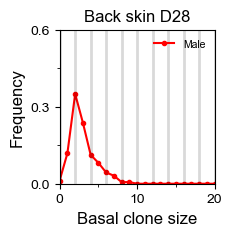

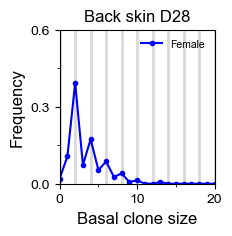

In [2]:
clone_data = pd.read_excel('BS_D28_Clone size.xlsx')

plt.figure(figsize=(2,2))
hist = np.histogram(clone_data[clone_data['sex'] == 'M']['basal'].values, bins=np.arange(0, 100, 1), density=True)
plt.plot(hist[1][:-1], hist[0], 'o-', markersize=3, linewidth=1.5, color = 'r')
plt.xlabel('Basal clone size')
plt.ylabel('Frequency')
plt.title('Back skin D28')
plt.xlim([0, 20])
plt.vlines(np.arange(0, 21, 2), 0, 1, color='k', ls='-', lw=2, alpha=0.15)
plt.ylim([0,0.6])
plt.yticks(np.linspace(0, 0.6, 5), minor = True)
plt.yticks([0, 0.3, 0.6])
plt.xticks(np.arange(0, 21, 10))
plt.xticks(np.arange(0, 21, 5), minor = True)
plt.legend(['Male'], frameon = False, loc='upper right')
plt.savefig('BS_D28_Clone size_M.pdf', bbox_inches='tight')
plt.show()


plt.figure(figsize=(2,2))
hist = np.histogram(clone_data[clone_data['sex'] == 'F']['basal'].values, bins=np.arange(0, 100, 1), density=True)
plt.plot(hist[1][:-1], hist[0], 'o-', markersize=3, linewidth=1.5, color = 'b')
plt.xlabel('Basal clone size')
plt.ylabel('Frequency')
plt.title('Back skin D28')
plt.xlim([0, 20])
plt.vlines(np.arange(0, 21, 2), 0, 1, color='k', ls='-', lw=2, alpha=0.15)
plt.ylim([0,0.6])
plt.yticks(np.linspace(0, 0.6, 5), minor = True)
plt.yticks([0, 0.3, 0.6])
plt.xticks(np.arange(0, 21, 10))
plt.xticks(np.arange(0, 21, 5), minor = True)
plt.legend(['Female'], frameon = False, loc='upper right')
plt.savefig('BS_D28_Clone size_F.pdf', bbox_inches='tight')
plt.show()

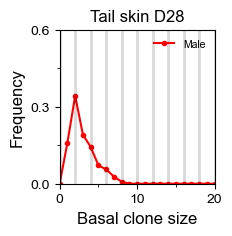

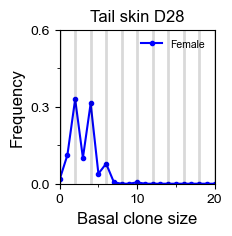

In [3]:
clone_data = pd.read_excel('Tail_D28_Clone size.xlsx')

plt.figure(figsize=(2,2))
hist = np.histogram(clone_data[clone_data['sex'] == 'M']['basal'].values, bins=np.arange(0, 100, 1), density=True)
plt.plot(hist[1][:-1], hist[0], 'o-', markersize=3, linewidth=1.5, color = 'r')
plt.xlabel('Basal clone size')
plt.ylabel('Frequency')
plt.title('Tail skin D28')
plt.xlim([0, 20])
plt.vlines(np.arange(0, 21, 2), 0, 1, color='k', ls='-', lw=2, alpha=0.15)
plt.ylim([0,0.6])
plt.yticks(np.linspace(0, 0.6, 5), minor = True)
plt.yticks([0, 0.3, 0.6])
plt.xticks(np.arange(0, 21, 10))
plt.xticks(np.arange(0, 21, 5), minor = True)
plt.legend(['Male'], frameon = False, loc='upper right')
plt.savefig('TS_D28_Clone size_M.pdf', bbox_inches='tight')
plt.show()


plt.figure(figsize=(2,2))
hist = np.histogram(clone_data[clone_data['sex'] == 'F']['basal'].values, bins=np.arange(0, 100, 1), density=True)
plt.plot(hist[1][:-1], hist[0], 'o-', markersize=3, linewidth=1.5, color = 'b')
plt.xlabel('Basal clone size')
plt.ylabel('Frequency')
plt.title('Tail skin D28')
plt.xlim([0, 20])
plt.vlines(np.arange(0, 21, 2), 0, 1, color='k', ls='-', lw=2, alpha=0.15)
plt.ylim([0,0.6])
plt.yticks(np.linspace(0, 0.6, 5), minor = True)
plt.yticks([0, 0.3, 0.6])
plt.xticks(np.arange(0, 21, 10))
plt.xticks(np.arange(0, 21, 5), minor = True)
plt.legend(['Female'], frameon = False, loc='upper right')
plt.savefig('TS_D28_Clone size_F.pdf', bbox_inches='tight')
plt.show()

In [4]:
from scipy.stats import ks_2samp, binomtest, ttest_ind
from scipy.stats import combine_pvalues
import numpy as np


def hist_to_sample(pdf, n_samples):
    hist_values = n_samples*pdf
    bin_values  = np.arange(0, len(hist_values))
    return np.concatenate([np.repeat(bin_values[i], hist_values[i]) for i in range(len(bin_values))])

def even_sizes_hypothesis_test(data, alpha=0.05, inc0=True, verbose=False):
    # Calculate the observed proportion of even-sized values
    data = data[~np.isnan(data)]  # Remove NaN values if present
    proportion_even = np.mean(data % 2 == 0)
    
    # Calculate the expected proportion of even-sized values assuming a geometric distribution
    if inc0:
        expected_proportion_even = 1 / (1 + np.floor(np.mean(data) / 2))
    else:
        expected_proportion_even = (np.mean(data) - 1)/(2*(np.mean(data)) - 1)
    
    # Perform the one-sample proportion test
    result = binomtest(k=np.sum(data % 2 == 0), n=len(data), p=expected_proportion_even, alternative='greater')
    
    if verbose:
        p_value = result.pvalue
        if p_value < alpha:
            print("Reject the null hypothesis (H0): The observed proportion differs significantly from the expected proportion.")
        else:
            print("Do not reject the null hypothesis (H0): The observed proportion does not significantly differ from the expected proportion.")
        
    return proportion_even, expected_proportion_even, result.pvalue



clone_data = pd.read_excel('BS_D28_Clone size.xlsx')
clone_data = pd.read_excel('Tail_D28_Clone size.xlsx')

for name in ['BS_D28_Clone size.xlsx', 'Tail_D28_Clone size.xlsx']:
    clone_data = pd.read_excel(name)


    ks_pval = np.zeros((2))
    M_ev_pval = np.zeros((2))
    F_ev_pval = np.zeros((2))
    M_expected_prop = np.zeros((2))
    F_expected_prop = np.zeros((2))
    prop_comparison_pval = np.zeros((2))


    #sample1 = np.histogram(clone_data[clone_data['sex'] == 'M']['basal'].values, bins=np.arange(0, 100, 1), density=True)[0]
    #sample2 = np.histogram(clone_data[clone_data['sex'] == 'F']['basal'].values, bins=np.arange(0, 100, 1), density=True)[0]
    sample1 = clone_data[clone_data['sex'] == 'M']['basal'].values
    sample2 = clone_data[clone_data['sex'] == 'F']['basal'].values
    sample1 = sample1[~np.isnan(sample1)]
    sample2 = sample2[~np.isnan(sample2)]

    # KS test for distribution differences
    statistic, p_value = ks_2samp(sample1, sample2)
    ks_pval[0] = p_value

    # Even bias tests
    _, M_expected, M_pval = even_sizes_hypothesis_test(sample1, inc0=False, verbose=False)
    _, F_expected, F_pval = even_sizes_hypothesis_test(sample2, inc0=False, verbose=False)

    M_ev_pval[0] = M_pval
    F_ev_pval[0] = F_pval
    M_expected_prop[0] = M_expected
    F_expected_prop[0] = F_expected

    sample1 = clone_data[clone_data['sex'] == 'M']['supra'].values
    sample2 = clone_data[clone_data['sex'] == 'F']['supra'].values
    sample1 = sample1[~np.isnan(sample1)]
    sample2 = sample2[~np.isnan(sample2)]

    # KS test for distribution differences
    statistic, p_value = ks_2samp(sample1, sample2)
    ks_pval[1] = p_value

    # Even bias tests
    _, M_expected, M_pval = even_sizes_hypothesis_test(sample1, inc0=True, verbose=False)
    _, F_expected, F_pval = even_sizes_hypothesis_test(sample2, inc0=True, verbose=False)

    M_ev_pval[1] = M_pval
    F_ev_pval[1] = F_pval
    M_expected_prop[1] = M_expected
    F_expected_prop[1] = F_expected

    print('Results for', name)
    print('KS p-values:', ks_pval)
    print('Even p-value, M:', M_ev_pval, 'F:', F_ev_pval)
    print()

Results for BS_D28_Clone size.xlsx
KS p-values: [0.15745047 0.61668304]
Even p-value, M: [8.42447309e-04 1.00000000e+00] F: [7.45580158e-15 1.00000000e+00]

Results for Tail_D28_Clone size.xlsx
KS p-values: [0.04041424 0.0025867 ]
Even p-value, M: [8.04142581e-07 1.00000000e+00] F: [2.98774251e-20 1.00000000e+00]

